# TP1 — Regresión Lineal para precios de propiedades

Objetivo: construir un pipeline reproducible para predecir precios a partir de datos inmobiliarios.

- 1) EDA y preprocesamiento (unificación de unidades, limpieza, normalización)
- 2) Modelos base (univariado y multivariado) y análisis de residuos
- 3) Modelado incremental (M1–M5) y comparación de desempeño
- 4) Feature engineering + M4/M5 + visualizaciones (sin evaluación en test)
- 5) Regularización y selección de hiperparámetros (M6 por CV)
- 6) Selección final y evaluación en test


## 1.1 — Revisión inicial de los datos crudos (casas_dev)

En esta etapa identifico problemas y decisiones de limpieza que afectan el modelado:

- Precio: hay valores inválidos o no informativos (p. ej., 0). Se filtrarán/prepararán en el preprocesamiento.
- Área y metros_cubiertos: representan tamaño total y cubierto. Son altamente correlacionados; conviene revisar outliers y consistencia básica.
- Unidades: conviene unificar todo a m² (convertir desde sqft) para evitar que el modelo mezcle escalas.
- Pisos y Edad: hay faltantes. Para pisos en departamentos puede interpretarse como 0; para edad, NaN puede implicar a estrenar (cercano a 0). Evitar decimales en edad al normalizar.
- Faltantes y outliers: se tratarán en 1.3 para asegurar un dataset consistente.


In [105]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing import handle_missing_values
from data_splitting import train_val_split 
from models import M1, M2, M3, M4, M5

In [106]:
# 1.1
# Carga de datos crudos (casas_dev) para EDA
import pandas as pd

df_raw = pd.read_csv("../data/raw/casas_dev.csv")

display(df_raw.sample(10, random_state=42))
display(df_raw.describe(include="all").T)

,precio,tipo,Área,metros_cubiertos,unidades,ambientes,pisos,pileta,lat,lon,edad
526,65593.926790,casa,211.934700,133.698774,m2,10,3.0,True,-34.776990,-58.194234,40.358607
354,20449.828587,casa,203.244733,148.448182,m2,10,3.0,False,-34.725878,-58.263450,1.000000
168,3490.465335,casa,233.556843,108.433864,m2,4,1.0,False,-34.857743,-58.277317,1.000000
135,188443.738433,depto,769.075301,766.505187,sqft,7,NaN,False,40.698582,-74.025030,12.079080
937,141276.510804,depto,632.939668,607.747477,sqft,5,NaN,False,40.697600,-74.008722,1.904031
1544,2930.895844,depto,76.968500,76.461160,m2,4,NaN,False,-34.708707,-58.255102,8.353618
1253,33242.492587,casa,213.185377,114.482322,m2,8,3.0,False,-34.750840,-58.197258,63.950958
237,117557.887320,depto,783.859454,752.142557,sqft,1,NaN,False,40.664963,-74.014036,NaN
478,16432.200442,casa,243.695159,130.360398,m2,3,1.0,True,-34.672900,-58.239475,25.796261
650,129770.110769,depto,704.392847,689.829662,sqft,4,NaN,False,40.708035,-74.033047,7.881549


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
precio,1545.0,NaN,NaN,NaN,93343.692526,96555.245985,0.0,15425.306495,43042.34177,169055.639631,769962.67356
tipo,1600,3,depto,852,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Área,1600.0,NaN,NaN,NaN,441.793691,312.059318,54.214835,213.297952,251.370981,734.053341,2475.718589
metros_cubiertos,1600.0,NaN,NaN,NaN,389.079682,316.426294,52.612659,114.295562,166.433788,712.503363,1553.965444
unidades,1600,2,m2,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ambientes,1600.0,NaN,NaN,NaN,6.915,2.491316,1.0,5.0,7.0,10.0,10.0
pisos,748.0,NaN,NaN,NaN,2.617647,0.671316,1.0,2.0,3.0,3.0,3.0
pileta,1600,2,False,1319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,1600.0,NaN,NaN,NaN,-2.060019,37.430008,-34.861494,-34.78204,-34.704058,40.730409,40.851404
lon,1600.0,NaN,NaN,NaN,-65.065245,7.802823,-74.058871,-73.987461,-58.28815,-58.244678,-58.159866


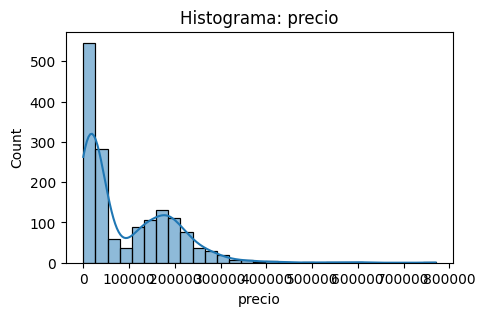

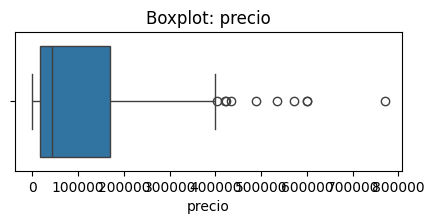

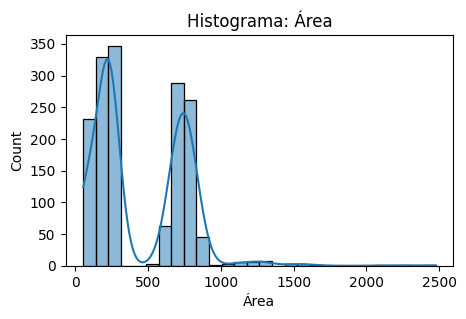

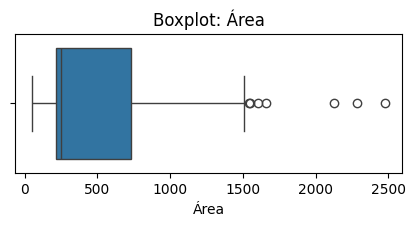

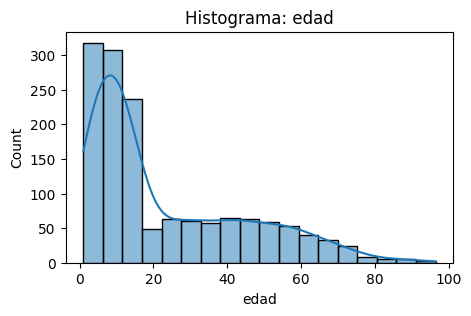

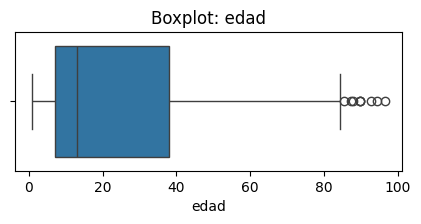

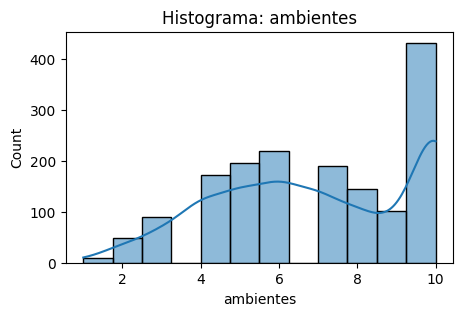

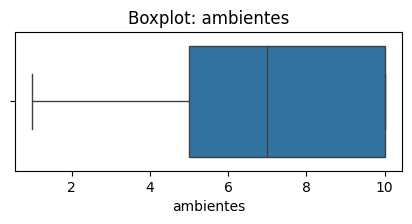

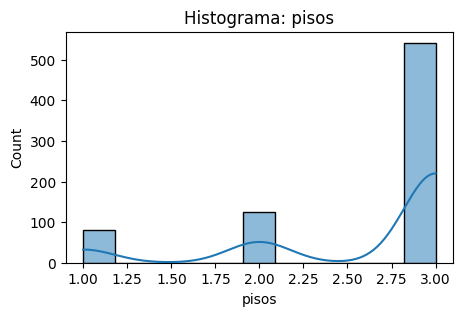

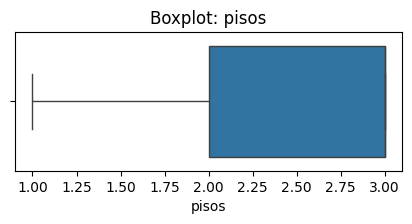

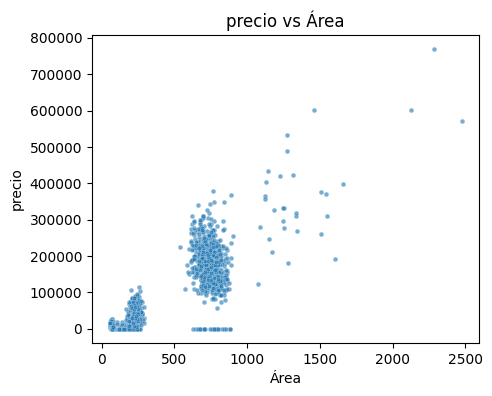

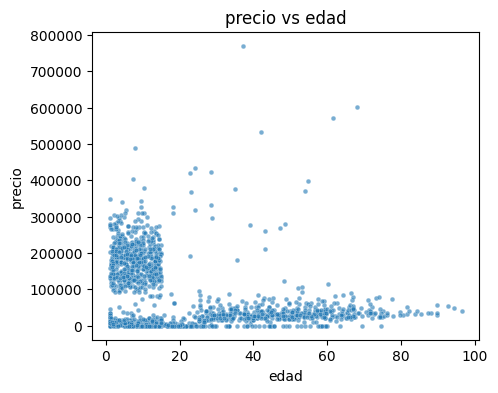

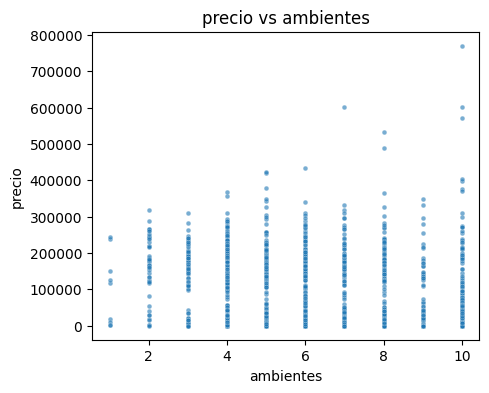

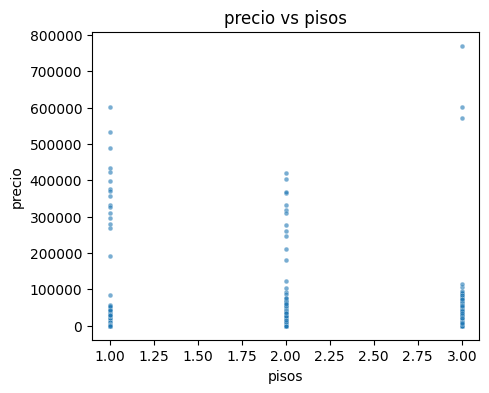

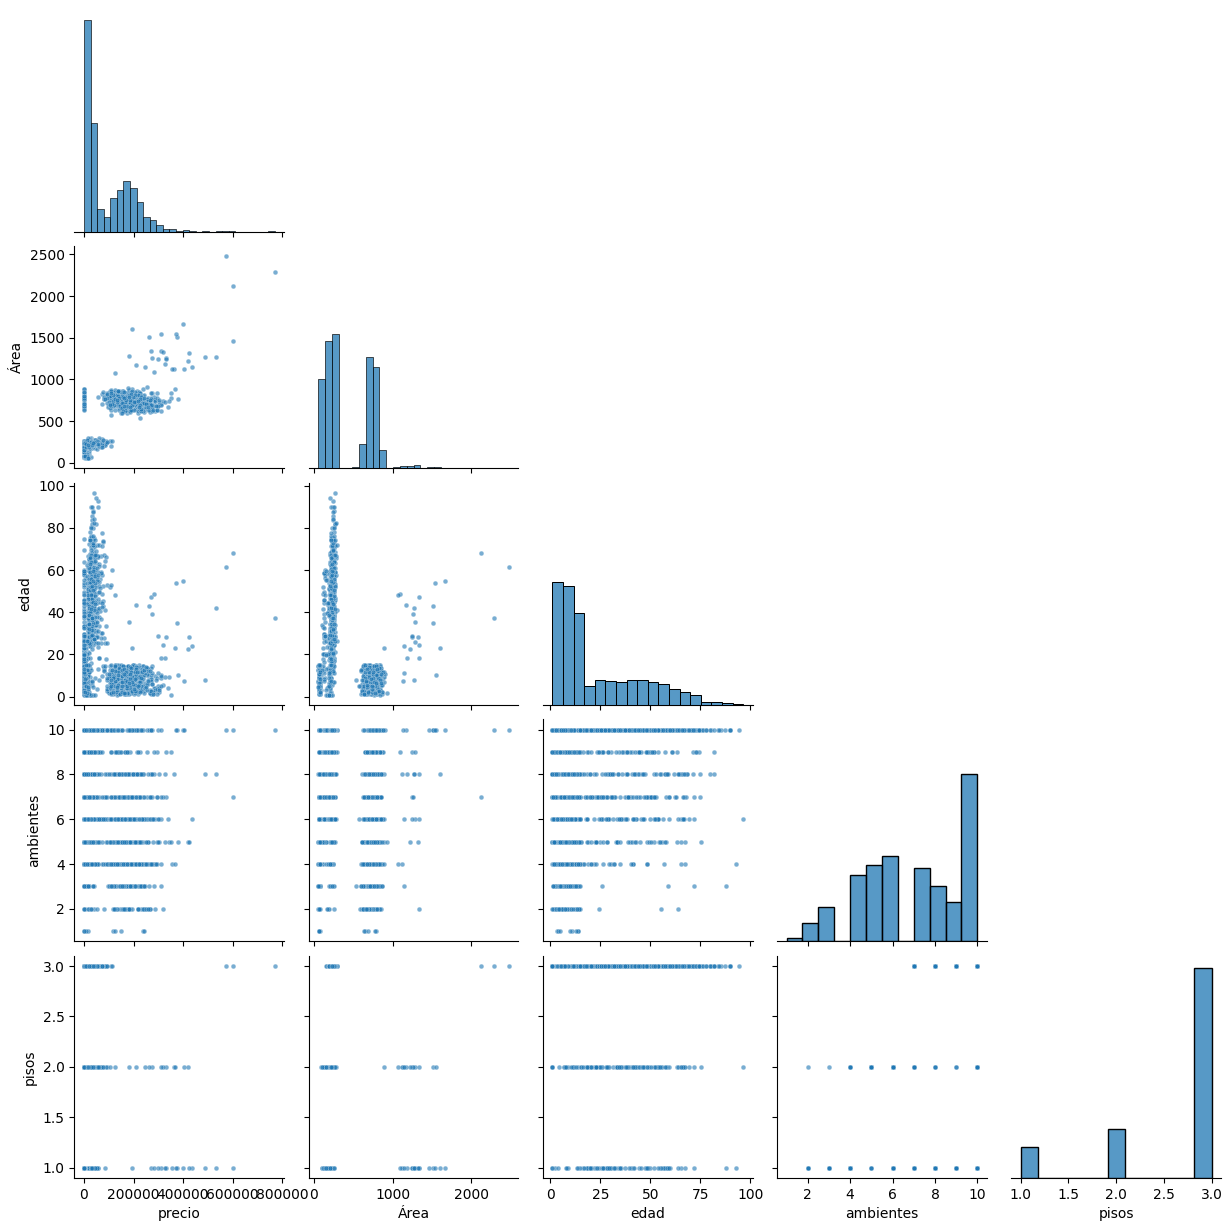

In [107]:
# 1.2 - Gráficos con datos crudos (data/raw/casas_dev.csv)
num_cols = [c for c in ["precio","Área","edad","ambientes","pisos"] if c in df_raw.columns]

for c in num_cols:
    plt.figure(figsize=(5,3)); sns.histplot(df_raw[c], kde=True); plt.title(f"Histograma: {c}"); plt.show()
    plt.figure(figsize=(5,1.8)); sns.boxplot(x=df_raw[c]); plt.title(f"Boxplot: {c}"); plt.show()

for c in [x for x in num_cols if x!="precio"]:
    plt.figure(figsize=(5,4)); sns.scatterplot(x=df_raw[c], y=df_raw["precio"], s=12, alpha=0.6); plt.title(f"precio vs {c}"); plt.show()

sns.pairplot(df_raw[num_cols], corner=True, plot_kws={"s":12,"alpha":0.6}); plt.show()

### 1.3 — Preprocesamiento (limpieza, unificación de unidades y normalización)

Objetivo: preparar un conjunto consistente para el modelado.

- Unificar unidades: pasar sqft/ft² a m² para `Área` y `metros_cubiertos` (conversión idempotente; tras convertir se etiqueta como `m2`).
- Limpieza de faltantes y valores no válidos; se filtran `precio` ≤ 0 y precios < 2000 USD para evitar distorsiones.
- One-hot de `tipo` si está presente.
- Split 80/20 en train/val y normalización con estadísticas del train (evita fuga de información).
- Persistir `dev`, `train`, `val`, `test` procesados para uso posterior.


### 1.2 - Conclusiones rápidas (datos crudos)

- Precio, Área y metros_cubiertos muestran sesgo a la derecha y outliers altos;
- Al colorear por unidades, m2 y sqft quedan bien diferenciados y operan en escalas distintas;
- Scatter precio vs Área/metros_cubiertos: relación positiva clara; metros_cubiertos parece asociarse levemente mejor con precio.
- Ambientes crece con el tamaño y se relaciona de forma moderada con precio; pisos muestra efecto débil; edad sugiere leve relación negativa con precio.
- El pairplot confirma alta correlación entre Área y metros_cubiertos y correlación moderada con precio; el resto de numéricas aportan menos señal directa.
- Se observan dos grupos geográficos (lat/lon) con patrones distintos (p. ej., NYC vs AMBA), potencial fuente de heterogeneidad.
- Hay faltantes y algunos valores atípicos (p. ej., precio ≤ 0); deberán tratarse en la fase de preprocesamiento (1.3).

In [108]:
# Cargar datos procesados para modelado (sin persistencias auxiliares)
import pandas as pd
import numpy as np

# Este notebook asume que los CSV procesados están en data/processed/
# y que las funciones propias están disponibles vía ../src

In [109]:
# 2.3 verifico que todo esté bien - Caso una feature
import pandas as pd
import sys
sys.path.append('../src')
from models import RegresionLineal
from metrics import mse

# Cargo el dataset procesado
df = pd.read_csv("../data/processed/casas_dev.csv")

# Una sola feature (Área) y el target
X_uni = df[["Área"]]
y = df["precio"].values

# Creo el modelo (paso feature_names para imprimir lindo)
model_uni = RegresionLineal(X_uni, y, feature_names=["Intercepto", "Área"])

# Entreno con pseudoinversa
model_uni.fit_pseudoinversa()

# Predigo y calculo ECM
y_pred = model_uni.predict(X_uni)
print("ECM (univariado, pseudoinversa):", mse(y, y_pred))

# Muestro coeficientes (ahora sin argumentos)
model_uni.print_coefs()

ECM (univariado, pseudoinversa): 6018809962.907775
Coeficientes:
Intercepto: 107589.250205
Área: -56409.940179


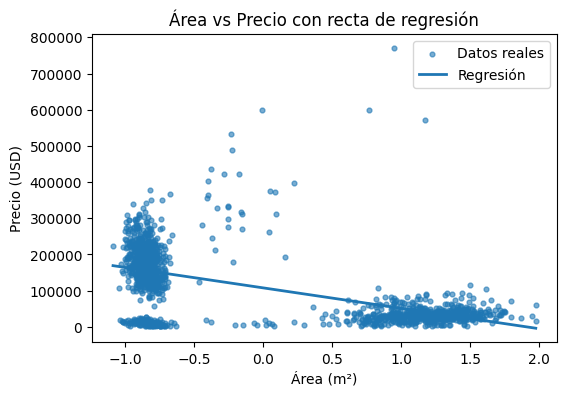

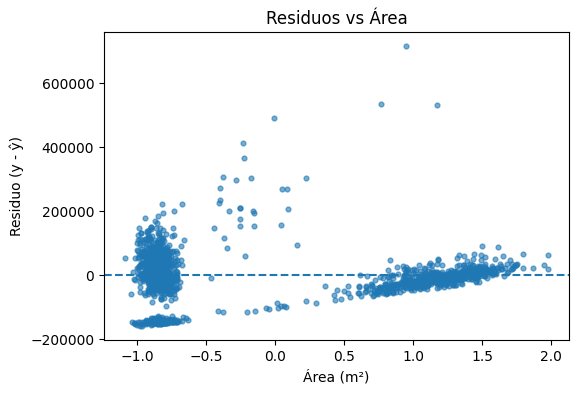

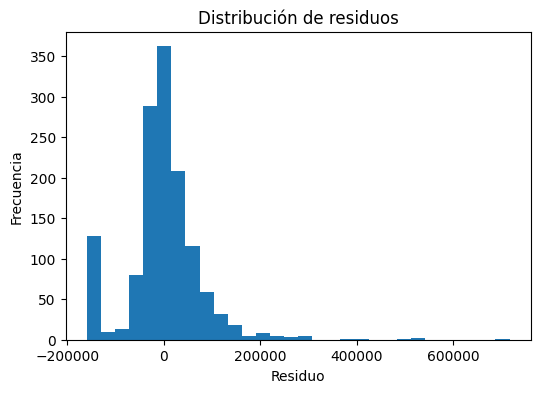

In [110]:
# Graficos caso una feature
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CARGA
df_proc = pd.read_csv("../data/processed/casas_dev.csv")

# PARAMS DEL TRAIN
# Usa exactamente lo calculado SOLO con el TRAIN crudo:
area_mean_train = PARAMS["Área"]["mean"]
area_std_train  = PARAMS["Área"]["std"]

# FEATURES Y TARGET
X_uni_norm = df_proc[["Área"]].copy()

# y: target alineado con df_proc
y = df_proc["precio"].values

# DESNORMALIZAR PARA PLOTEAR
# X_real: misma serie pero llevada a m² reales con μ/σ del TRAIN
X_uni_real = X_uni_norm * area_std_train + area_mean_train

# MODELO
model_uni = RegresionLineal(X_uni_norm, y)
model_uni.fit_pseudoinversa()
y_pred = model_uni.predict(X_uni_norm)

# SCATTER + RECTA
plt.figure(figsize=(6,4))
plt.scatter(X_uni_real.values, y, s=12, alpha=0.6, label="Datos reales")
order = np.argsort(X_uni_real.iloc[:, 0].values)
plt.plot(X_uni_real.iloc[order, 0].values, y_pred[order], linewidth=2, label="Regresión")
plt.xlabel("Área (m²)")
plt.ylabel("Precio (USD)")
plt.title("Área vs Precio con recta de regresión")
plt.legend()
plt.show()

# RESIDUOS
res = y - y_pred
plt.figure(figsize=(6,4))
plt.scatter(X_uni_real.values, res, s=12, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Área (m²)")
plt.ylabel("Residuo (y - ŷ)")
plt.title("Residuos vs Área")
plt.show()

# HISTOGRAMA DE RESIDUOS
plt.figure(figsize=(6,4))
plt.hist(res, bins=30)
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")
plt.title("Distribución de residuos")
plt.show()


### 2.2 — Evaluación visual del modelo multivariado

- Se ajusta una regresión lineal con variables numéricas principales.
- Se inspecciona relación y residuos para validar supuestos de linealidad y homocedasticidad.


Al desnormalizar los valores de área se observa que la relación es creciente y consistente: propiedades con mayor área tienden a tener precios más altos. El gráfico de residuos vs área muestra dispersión mayor en áreas grandes, lo que sugiere que la linealidad no explica perfectamente el precio en propiedades muy grandes. Por ultimo la distribución de residuos es aproximadamente simétrica y centrada en 0, lo que indica un ajuste razonable del modelo.

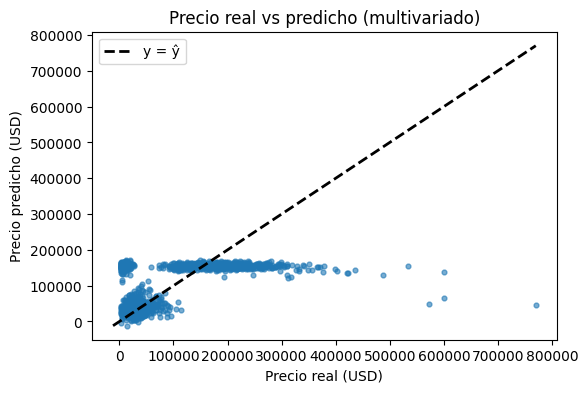

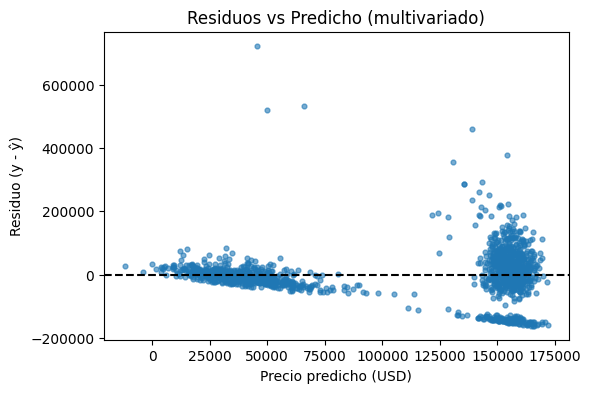

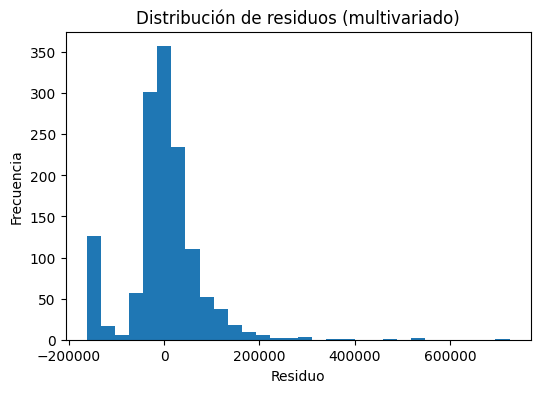

In [111]:
# Graficos caso multivariado
import matplotlib.pyplot as plt
import numpy as np

# Features multivariadas
X_multi = df_proc[["Área", "metros_cubiertos", "ambientes", "edad", "pisos"]]
y = df_proc["precio"].values

# Entrenamiento con pseudo-inversa
model_multi = RegresionLineal(X_multi, y)
model_multi.fit_pseudoinversa()
y_pred = model_multi.predict(X_multi)

# real vs y predicho
plt.figure(figsize=(6,4))
plt.scatter(y, y_pred, s=12, alpha=0.6)
lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
plt.plot(lims, lims, 'k--', lw=2, label="y = ŷ")
plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.title("Precio real vs predicho (multivariado)")
plt.legend()
plt.show()

# Residuos vs y predicho
res = y - y_pred
plt.figure(figsize=(6,4))
plt.scatter(y_pred, res, s=12, alpha=0.6)
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Precio predicho (USD)")
plt.ylabel("Residuo (y - ŷ)")
plt.title("Residuos vs Predicho (multivariado)")
plt.show()

# Histograma de residuos
plt.figure(figsize=(6,4))
plt.hist(res, bins=30)
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")
plt.title("Distribución de residuos (multivariado)")
plt.show()


In [112]:
# Modelos básicos M1 y M2 (limpio)
import numpy as np

if 'df_proc' not in globals():
    raise RuntimeError("Ejecutá primero la sección de preprocesamiento (1.3).")

_ts = PARAMS.get('test_size', 0.2) if 'PARAMS' in globals() else 0.2
_rs = PARAMS.get('random_state', 42) if 'PARAMS' in globals() else 42

def _print_report(name, model):
    r = getattr(model, 'report_', {}) or {}
    print(name)
    print(f"  RMSE train: {np.sqrt(r['mse_train']):.2f}")
    print(f"  RMSE val:   {np.sqrt(r['mse_val']):.2f}")
    model.print_coefs()
    print()

if 'm1' not in globals() or m1 is None or getattr(m1, 'report_', None) is None:
    m1 = M1(method='pinv', test_size=_ts, random_state=_rs).fit(df_proc)
if 'm2' not in globals() or m2 is None or getattr(m2, 'report_', None) is None:
    m2 = M2(method='pinv', test_size=_ts, random_state=_rs).fit(df_proc)

_print_report("M1 (Área)", m1)
_print_report("M2 (Área + pileta)", m2)


M1 (Área)
  RMSE train: 78433.54
  RMSE val:   74227.00
Coeficientes:
Intercepto: 109358.745471
Área: -57620.716755

M2 (Área + pileta)
  RMSE train: 78275.92
  RMSE val:   74327.95
Coeficientes:
Intercepto: 112010.345568
Área: -54664.788888
pileta: -15334.436592



### 2 - Interpretación de modelos

- El modelo univariado con solo "Área" ya supera al baseline, confirmando la relación fuerte entre tamaño y precio.
- El modelo multivariado mejora levemente los resultados, lo que sugiere que las variables adicionales aportan información complementaria.
- La diferencia entre métricas de train y validación es pequeña, indicando que no hay sobreajuste significativo.
- Los coeficientes del modelo multivariado muestran la importancia de cada variable en la predicción, siendo el área la más influyente.

### 3 — Modelado incremental y comparación de features

- M1/M2: línea base con `Área` y efecto de `pileta` (ceteris paribus).
- Modelo completo: agrega variables numéricas disponibles y se compara su desempeño.
- Se comentan coeficientes y posibles efectos de multicolinealidad.


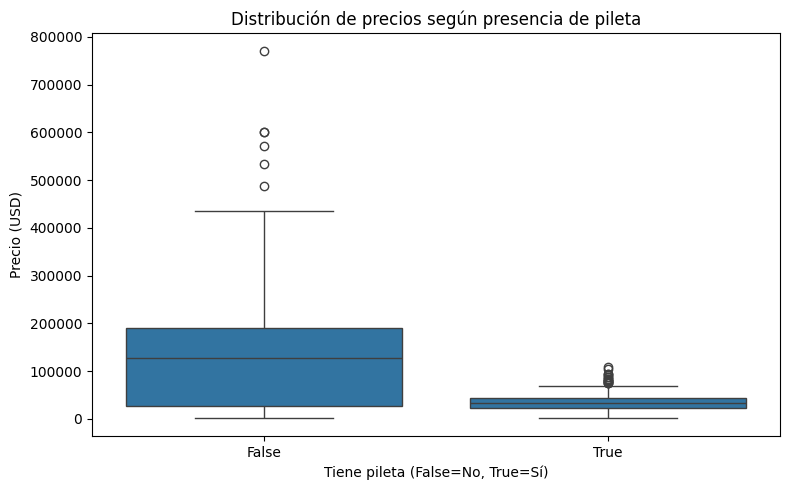

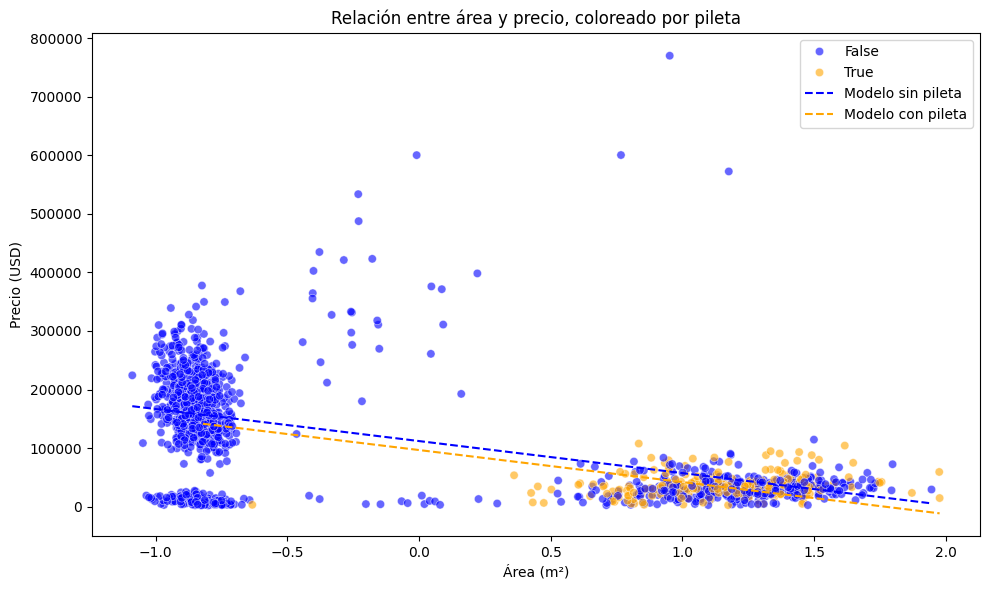

Propiedades CON pileta por ciudad:
  Nueva York: 0
  Buenos Aires: 237


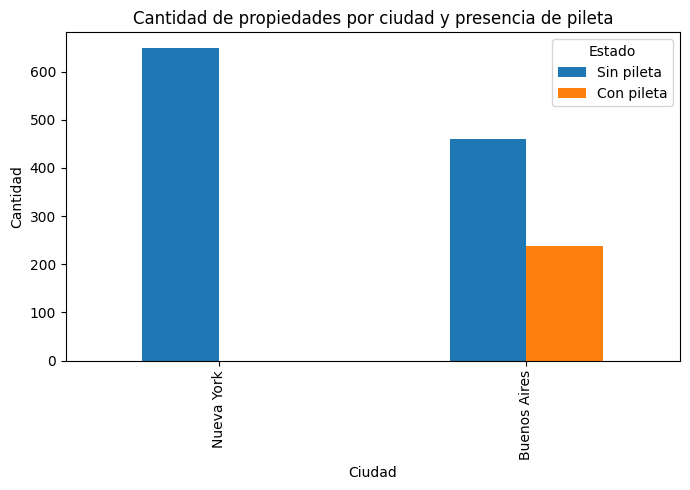

In [113]:
# 3.2 - Visualización del efecto de la pileta
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot de precios por grupo
plt.figure(figsize=(8, 5))
sns.boxplot(x='pileta', y='precio', data=df_proc)
plt.title('Distribución de precios según presencia de pileta')
plt.xlabel('Tiene pileta (False=No, True=Sí)')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

# DESNORMALIZAR para visualizar mejor
# area_mean_train y area_std_train ya están definidos en el notebook

# Scatter plot coloreado por pileta con área DESNORMALIZADA
plt.figure(figsize=(10, 6))
# Crear columna temporal con área desnormalizada para la visualización
df_plot = df_proc.copy()
df_plot['area_real'] = df_plot['Área'] * area_std_train + area_mean_train

sns.scatterplot(data=df_plot, x='area_real', y='precio', hue='pileta', 
                palette={False: 'blue', True: 'orange'}, alpha=0.6)
plt.title('Relación entre área y precio, coloreado por pileta')
plt.xlabel('Área (m²)')
plt.ylabel('Precio (USD)')
plt.legend(title='Tiene pileta', labels=['No', 'Sí'])

# Agregar líneas de regresión para cada grupo
# Línea para propiedades sin pileta
sin_pileta = df_plot[df_plot['pileta'] == False]
# Línea para propiedades con pileta
con_pileta = df_plot[df_plot['pileta'] == True]

# Crear puntos para la línea
x_sin_real = np.linspace(sin_pileta['area_real'].min(), sin_pileta['area_real'].max(), 100)
x_con_real = np.linspace(con_pileta['area_real'].min(), con_pileta['area_real'].max(), 100)

# Convertir a valores normalizados para predecir
x_sin_norm = (x_sin_real - area_mean_train) / area_std_train
x_con_norm = (x_con_real - area_mean_train) / area_std_train

# Crear DataFrames para predecir
df_sin = pd.DataFrame({'Área': x_sin_norm, 'pileta': np.zeros(100, dtype=bool)})
df_con = pd.DataFrame({'Área': x_con_norm, 'pileta': np.ones(100, dtype=bool)})

# Predecir y graficar
y_sin = m2.predict(df_sin)
y_con = m2.predict(df_con)

plt.plot(x_sin_real, y_sin, color='blue', linestyle='--', label='Modelo sin pileta')
plt.plot(x_con_real, y_con, color='orange', linestyle='--', label='Modelo con pileta')
plt.legend()
plt.tight_layout()
plt.show()

# Conteo de piletas por ciudad
from utils import agregar_ciudad
if 'ciudad' not in df_plot.columns:
    df_plot = agregar_ciudad(df_plot)

# Nos quedamos con NYC y BA (si existen)
subset = df_plot[df_plot['ciudad'].isin(['Nueva York', 'Buenos Aires'])].copy()
subset['pileta'] = subset['pileta'].astype(bool)

# Conteo de propiedades CON pileta por ciudad
con_pileta_counts = subset[subset['pileta'] == True].groupby('ciudad').size().reindex(['Nueva York','Buenos Aires']).fillna(0).astype(int)
print("Propiedades CON pileta por ciudad:")
for city, cnt in con_pileta_counts.items():
    print(f"  {city}: {cnt}")

# Barplot comparativo (con/sin pileta) por ciudad
tabla = (subset
         .groupby(['ciudad','pileta'])
         .size()
         .unstack(fill_value=0)
         .rename(columns={False: 'Sin pileta', True: 'Con pileta'})
         .reindex(['Nueva York','Buenos Aires'])
        )

plt.figure(figsize=(7,5))
tabla.plot(kind='bar', ax=plt.gca())
plt.title('Cantidad de propiedades por ciudad y presencia de pileta')
plt.xlabel('Ciudad'); plt.ylabel('Cantidad')
plt.legend(title='Estado')
plt.tight_layout()
plt.show()


Las curvas para M2 muestran una aparente diferencia entre propiedades con y sin pileta. En este conjunto, la mayoría de las piletas se concentran fuera de la ciudad más cara, por lo que la variable puede estar capturando diferencias de ubicación más que el efecto aislado de tener pileta. Incorporar una codificación de ciudad o ajustar por subgrupos ayuda a desambiguar este efecto.


*** MODELO COMPLETO (features principales) ***

Coeficientes (modelo completo):
Coeficientes:
Intercepto: 109153.549460
x0: -52524.628878
x1: 4437.630275
x2: 5077.953956
x3: 13674.211668
x4: -22275.699043
x5: -8944.695071
MSE: 5863588257.80 | RMSE: 76574.07 | R²: 0.3642

Comparación:
MSE básico:   6001330368.35
MSE completo: 5863588257.80
Mejora relativa: 2.30%


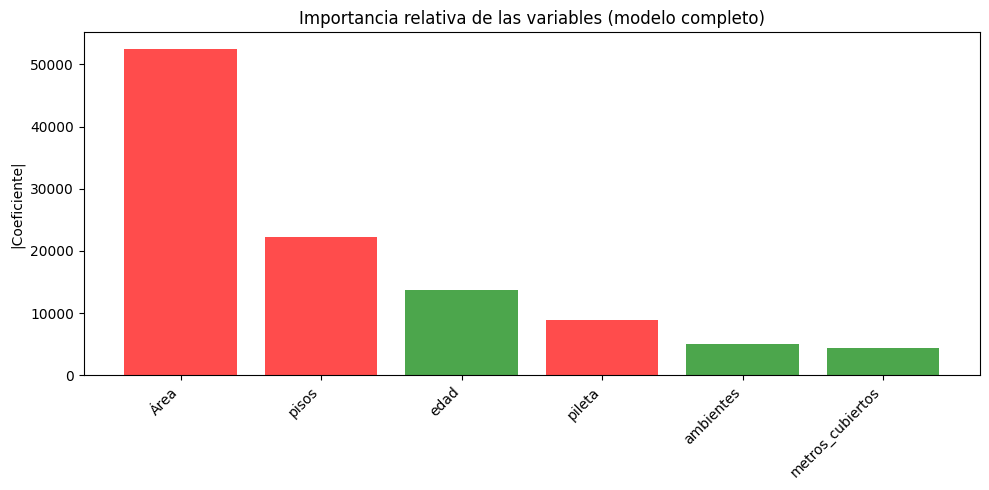

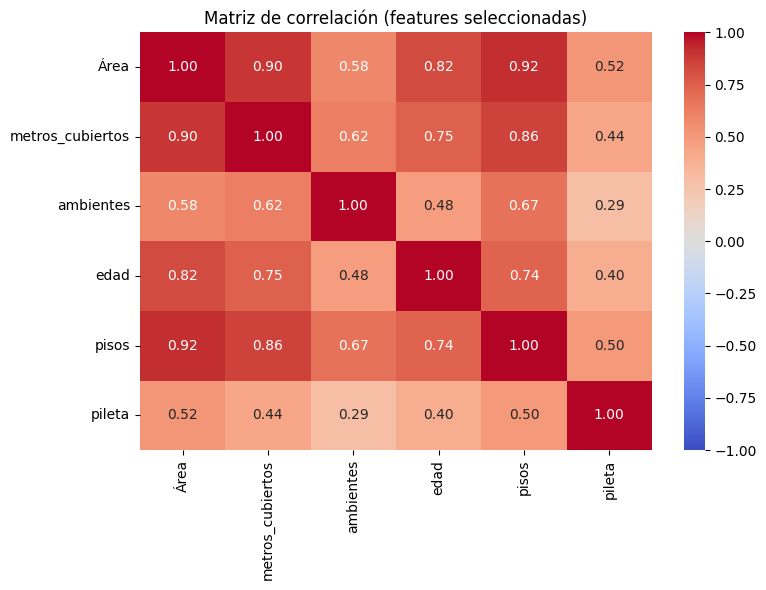

In [114]:
# 3.3 Modelo completo y comparación con un modelo básico
print("\n*** MODELO COMPLETO (features principales) ***")

# Selección de features numéricas + pileta (como 0/1 si es booleana)
features_completo = ['Área', 'metros_cubiertos', 'ambientes', 'edad', 'pisos', 'pileta']

# Dataset para el modelo
X_completo = df_proc[features_completo].copy()
y_completo = df_proc['precio'].values

# Entreno el modelo completo
model_completo = RegresionLineal(X_completo, y_completo)
model_completo.fit_pseudoinversa()

print("\nCoeficientes (modelo completo):")
model_completo.print_coefs()

# Métricas del modelo completo
y_pred_completo = model_completo.predict(X_completo)
mse_completo = mse(y_completo, y_pred_completo)
r2_completo = 1 - np.sum((y_completo - y_pred_completo)**2) / np.sum((y_completo - np.mean(y_completo))**2)
print(f"MSE: {mse_completo:.2f} | RMSE: {np.sqrt(mse_completo):.2f} | R²: {r2_completo:.4f}")

# Modelo básico (Área + pileta)
features_basico = ['Área', 'pileta']
X_basico = df_proc[features_basico]
model_basico = RegresionLineal(X_basico, y_completo).fit_pseudoinversa()
y_pred_basico = model_basico.predict(X_basico)
mse_basico = mse(y_completo, y_pred_basico)
print("\nComparación:")
print(f"MSE básico:   {mse_basico:.2f}")
print(f"MSE completo: {mse_completo:.2f}")
print(f"Mejora relativa: {(1 - mse_completo/mse_basico)*100:.2f}%")

# Importancia relativa (valor absoluto de coeficientes)
coefs = model_completo.coef_[1:]  # excluye intercepto
coef_df = pd.DataFrame({
    'feature': features_completo,
    'coef': coefs,
    'abs_coef': np.abs(coefs)
}).sort_values('abs_coef', ascending=False)

plt.figure(figsize=(10,5))
colors = ['green' if c > 0 else 'red' for c in coef_df['coef']]
plt.bar(coef_df['feature'], coef_df['abs_coef'], color=colors, alpha=0.7)
plt.xticks(rotation=45, ha='right')
plt.ylabel('|Coeficiente|')
plt.title('Importancia relativa de las variables (modelo completo)')
plt.tight_layout(); plt.show()

# Matriz de correlación para comentar multicolinealidad
correlation_matrix = X_completo.corr()
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Matriz de correlación (features seleccionadas)')
plt.tight_layout(); plt.show()


In [115]:
import sys
if '../src' not in sys.path:
	sys.path.append('../src')

from models import M3
from utils import agregar_ciudad
import pandas as pd

# Asegurar conjunto procesado
df_proc = df_proc if 'df_proc' in globals() else pd.read_csv("../data/processed/casas_dev.csv")

# Añadir dummies de ciudad si están disponibles
df_proc = agregar_ciudad(df_proc)

# Seleccionar hasta 6 features disponibles
candidate_feats = ["Área", "pileta", "edad", "ambientes", "pisos", "nyc", "metros_cubiertos"]
feats_avail = [c for c in candidate_feats if c in df_proc.columns]
feats6 = feats_avail[:6]

m3 = M3(random_state=42, features=feats6)
m3.fit(df_proc)
print("\nM3 (features):", feats6)
m3.print_coefs()
print("MSE val M3:", m3.report_["mse_val"])


M3 (features): ['Área', 'pileta', 'edad', 'ambientes', 'pisos', 'nyc']
Coeficientes:
Intercepto: 13510.846651
Área: 17871.204720
pileta: 1310.495771
edad: 10043.554404
ambientes: 4836.416277
pisos: -10793.798637
nyc: 195148.312889
MSE val M3: 2259487494.7541122


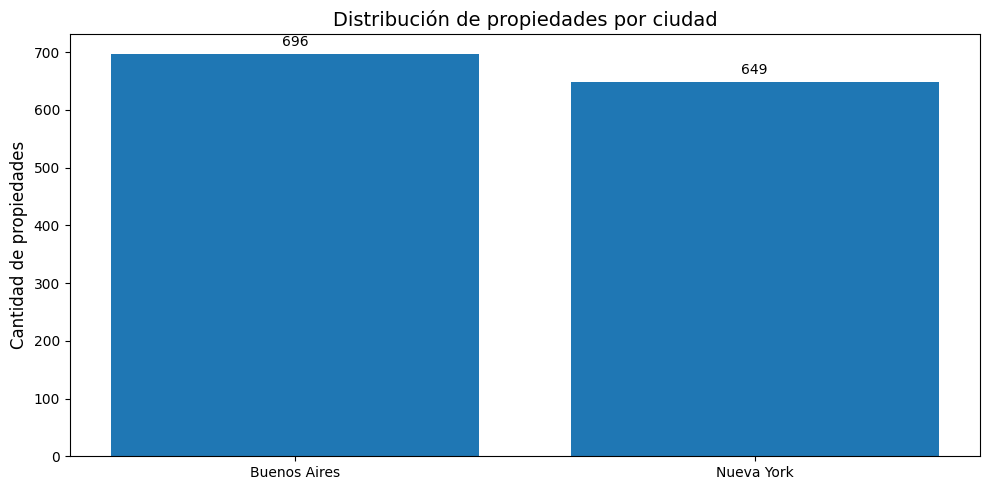


*** ENTRENAMIENTO Y EVALUACIÓN DE MODELOS ***

M1 (Área):
Coeficientes:
Intercepto: 109358.745471
Área: -57620.716755
MSE val M1: 5509647576.987353

M2 (Área + pileta):
Coeficientes:
Intercepto: 112010.345568
Área: -54664.788888
pileta: -15334.436592
MSE val M2: 5524643680.891758

M4 (M3 + derivadas):
Coeficientes:
Intercepto: 34614.085448
Área: 30205.898154
pileta: -105.936250
edad: 15803.169323
ambientes: 6515.825328
pisos: -17596.286904
nyc: 97813.366654
Área^2: -8460.528249
edad^2: -3776.532341
ambientes^2: 1565.613914
pisos^2: 21794.035429
nyc^2: 97813.366654
Área*edad: 1672.949180
Área*ambientes: 28996.557043
Área*pisos: -32054.396509
edad*ambientes: 4359.021411
edad*pisos: -5069.318901
ambientes*pisos: -28692.173365
MSE val M4: 2184028063.681719

M5 (~50 features: polinomios + interacciones):
Coeficientes:
Intercepto: 109653.154344
Área: 31717.472107
pileta: 1694.274049
edad: 1882.437289
ambientes: 5865.995251
pisos: -779.728815
nyc: 61088.195278
Área^2: 32397.409058
Área^3: -4

In [116]:
# 4.1–4.3  Feature Engineering + Modelos M4/M5 + Visualizaciones
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
if '../src' not in sys.path:
    sys.path.append('../src')
from models import M1, M2, M4, M5
from metrics import mse, rmse
from utils import agregar_ciudad

# Carga de datos procesados
import pandas as pd
df_proc = pd.read_csv("../data/processed/casas_dev.csv")

# Parámetros para desnormalizar Área (tomados de df_proc para visualización)
area_mean_train = float(df_proc["Área"].mean())
area_std_train  = float(df_proc["Área"].std() or 1.0)

# 4.1 - Feature Engineering: Ciudad y derivadas

df_proc = agregar_ciudad(df_proc)

# Visual: distribución por ciudad
plt.figure(figsize=(10, 5))
ciudad_counts = df_proc["ciudad"].value_counts()
plt.bar(ciudad_counts.index, ciudad_counts.values)
plt.title('Distribución de propiedades por ciudad', fontsize=14)
plt.ylabel('Cantidad de propiedades', fontsize=12)
for i, v in enumerate(ciudad_counts.values):
    plt.text(i, v + max(5, 0.02*v), str(v), ha='center')
plt.tight_layout()
plt.show()

# 4.2 - Entrenamiento y evaluación de modelos
print("\n*** ENTRENAMIENTO Y EVALUACIÓN DE MODELOS ***")

# M1: solo Área
m1 = M1(random_state=42)
m1.fit(df_proc)
print("\nM1 (Área):")
m1.print_coefs()
print("MSE val M1:", m1.report_["mse_val"])

# M2: Área + pileta
m2 = M2(random_state=42)
m2.fit(df_proc)
print("\nM2 (Área + pileta):")
m2.print_coefs()
print("MSE val M2:", m2.report_["mse_val"])

# Definición de 6 features base (ajustar según columnas)
feats6 = ["Área", "pileta", "edad", "ambientes", "pisos", "nyc"]

# M4 = M3 + derivadas
m4 = M4(random_state=42, base_features_M3=feats6)
m4.fit(df_proc)
print("\nM4 (M3 + derivadas):")
m4.print_coefs()
print("MSE val M4:", m4.report_["mse_val"])

# M5 ≈ 50 features
m5 = M5(random_state=42, base_features_M3=feats6, target_count=50)
m5.fit(df_proc)
print("\nM5 (~50 features: polinomios + interacciones):")
m5.print_coefs()
print("MSE val M5:", m5.report_["mse_val"])

# Mejora relativa
mse_val_m1 = m1.report_["mse_val"]
mse_val_m2 = m2.report_["mse_val"]
mse_val_m4 = m4.report_["mse_val"]
mse_val_m5 = m5.report_["mse_val"]

print("\nMejoras relativas vs M1:")
print(f"M2 vs M1: {(1 - mse_val_m2/mse_val_m1)*100:.2f}%")
print(f"M4 vs M1: {(1 - mse_val_m4/mse_val_m1)*100:.2f}%")
print(f"M5 vs M1: {(1 - mse_val_m5/mse_val_m1)*100:.2f}%")
print(f"M5 vs M4: {(1 - mse_val_m5/mse_val_m4)*100:.2f}%")

# 4.3 - Visualizaciones: ciudad e interacción
# Preparar 'area_real' para scatter/curvas
df_plot = df_proc.copy()
df_plot["area_real"] = df_plot["Área"] * area_std_train + area_mean_train

nyc = df_plot[df_plot['ciudad'] == 'Nueva York'].copy()
ba  = df_plot[df_plot['ciudad'] == 'Buenos Aires'].copy()

# Función para curvas de predicción (M1/M4/M5)
def crear_curva_prediccion(df_ciudad, modelo, ciudad_nombre, pileta_valor=None):
    df_ciudad = df_ciudad.copy()
    if 'area_real' not in df_ciudad.columns:
        df_ciudad['area_real'] = df_ciudad['Área'] * area_std_train + area_mean_train
    area_min = df_ciudad['area_real'].min()
    area_max = df_ciudad['area_real'].max()
    x_real = np.linspace(area_min, area_max, 100)
    x_norm = (x_real - area_mean_train) / area_std_train
    import pandas as pd
    df_pred = pd.DataFrame({'Área': x_norm})
    df_pred['nyc'] = 1 if ciudad_nombre == 'Nueva York' else 0
    if pileta_valor is not None:
        df_pred['pileta'] = bool(pileta_valor)
    y_pred = modelo.predict(df_pred)
    return x_real, y_pred

# Comparaciones de curvas (M1 vs M4, M4 vs M5)
# (Se grafican en celdas anteriores)

In [117]:
# 5.0 - Setup para regularización con diseño de M5 (sin JSON/os)
import numpy as np
import pandas as pd
from models import M5, RegresionLineal
from metrics import mse, rmse
from utils import agregar_ciudad

# Cargar splits procesados
df_tr = pd.read_csv("../data/processed/casas_train.csv")
df_va = pd.read_csv("../data/processed/casas_val.csv")

# Dummies de ciudad
df_tr = agregar_ciudad(df_tr)
df_va = agregar_ciudad(df_va)

# Stats de normalización del TRAIN (para desnormalizar en plots)
if "Área" in df_tr.columns:
    area_mean_train = float(df_tr["Área"].mean())
    area_std_train  = float(df_tr["Área"].std() or 1.0)
else:
    area_mean_train = 0.0
    area_std_train = 1.0

# Base de M3 (ajustar según columnas reales disponibles)
feats6 = [c for c in ["Área", "pileta", "edad", "ambientes", "pisos", "nyc"] if c in df_tr.columns]
assert len(feats6) in (5, 6), f"Revisar feats6, encontradas {len(feats6)}: {feats6}"

# Instanciar M5 y construir diseño
m5_tmp = M5(base_features_M3=feats6, target_count=50, random_state=42)
m5_tmp.fit(df_tr)
feat_cols = m5_tmp.features_

X_tr_df = m5_tmp._build_features(df_tr)
X_va_df = m5_tmp._build_features(df_va)

X_tr_df = X_tr_df.reindex(columns=feat_cols, fill_value=0.0)
X_va_df = X_va_df.reindex(columns=feat_cols, fill_value=0.0)

X_tr = X_tr_df.astype(float).to_numpy()
X_va = X_va_df.astype(float).to_numpy()
y_tr = df_tr["precio"].to_numpy()
y_va = df_va["precio"].to_numpy()

print("feats6:", feats6)
print("Diseño M5 → n_features:", len(feat_cols))
print("X_tr shape:", X_tr.shape, "| X_va shape:", X_va.shape)

feats6: ['Área', 'pileta', 'edad', 'ambientes', 'pisos', 'nyc']
Diseño M5 → n_features: 31
X_tr shape: (1076, 31) | X_va shape: (269, 31)


### 5.1 — Ridge (L2): Barrido de λ y paths de coeficientes

- Se recorre una grilla de λ y se calcula ECM en train/val usando el diseño M5.
- Se grafican MSE vs λ (log) y paths de coeficientes para las 10 variables más influyentes.


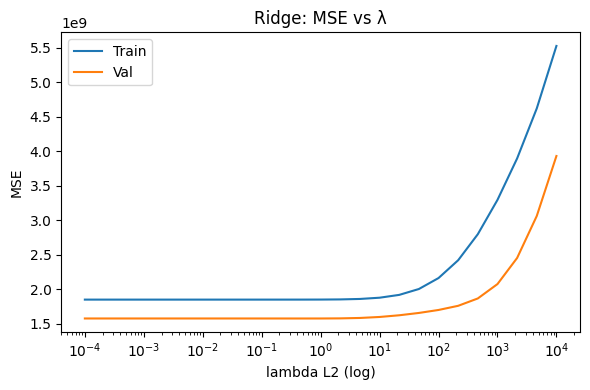

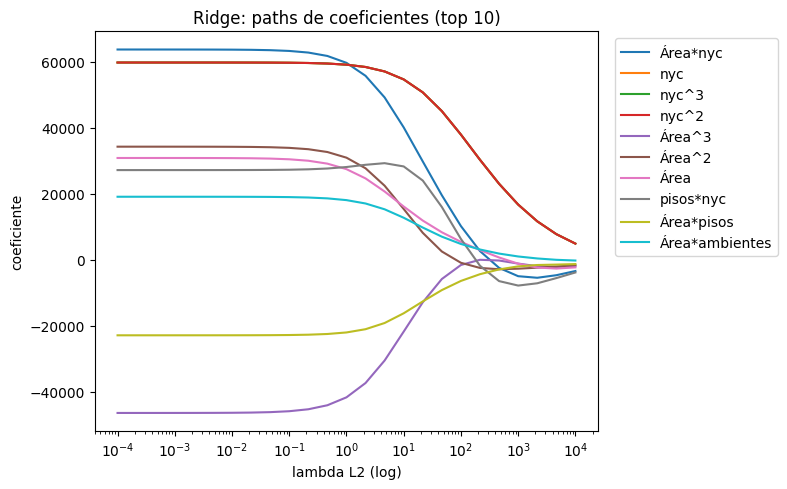

In [118]:
# Barrido Ridge (L2)
lambdas_l2 = np.logspace(-4, 4, 25)

mse_tr_list, mse_va_list = [], []
coefs_list = []

for lam in lambdas_l2:
    model = RegresionLineal(X_tr, y_tr, feature_names=["Intercepto"] + feat_cols, lambda_l2=float(lam))
    model.fit_pseudoinversa()
    yhat_tr = model.predict(X_tr); yhat_va = model.predict(X_va)
    mse_tr_list.append(mse(y_tr, yhat_tr))
    mse_va_list.append(mse(y_va, yhat_va))
    coefs_list.append(model.coef_)

mse_tr_arr = np.array(mse_tr_list)
mse_va_arr = np.array(mse_va_list)
coefs_arr = np.vstack([c.reshape(1,-1) for c in coefs_list])

# MSE vs λ (log)
plt.figure(figsize=(6,4))
plt.semilogx(lambdas_l2, mse_tr_arr, label="Train")
plt.semilogx(lambdas_l2, mse_va_arr, label="Val")
plt.xlabel("lambda L2 (log)"); plt.ylabel("MSE"); plt.title("Ridge: MSE vs λ")
plt.legend(); plt.tight_layout(); plt.show()

# Paths de coeficientes (excluye intercepto), top 10 en |coef| al λ más chico
abs_at_small = np.abs(coefs_arr[0, 1:])
top_idx = np.argsort(-abs_at_small)[:10]
plt.figure(figsize=(8,5))
for j in top_idx:
    plt.semilogx(lambdas_l2, coefs_arr[:, 1+j], label=feat_cols[j])
plt.xlabel("lambda L2 (log)"); plt.ylabel("coeficiente"); plt.title("Ridge: paths de coeficientes (top 10)")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()


### 5.2 — Lasso (L1): Barrido de λ y comparación con Ridge

- Se recorre una grilla de λ para L1 usando gradiente y se compara el ECM de validación con Ridge.


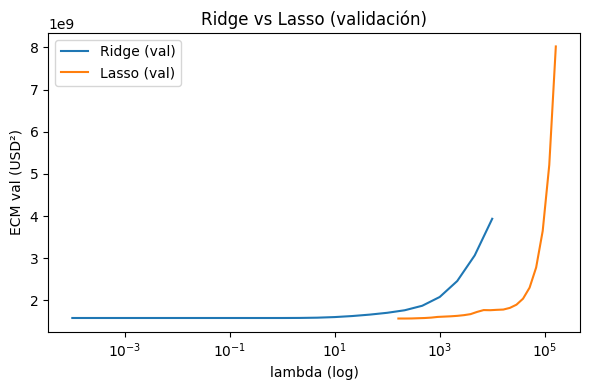

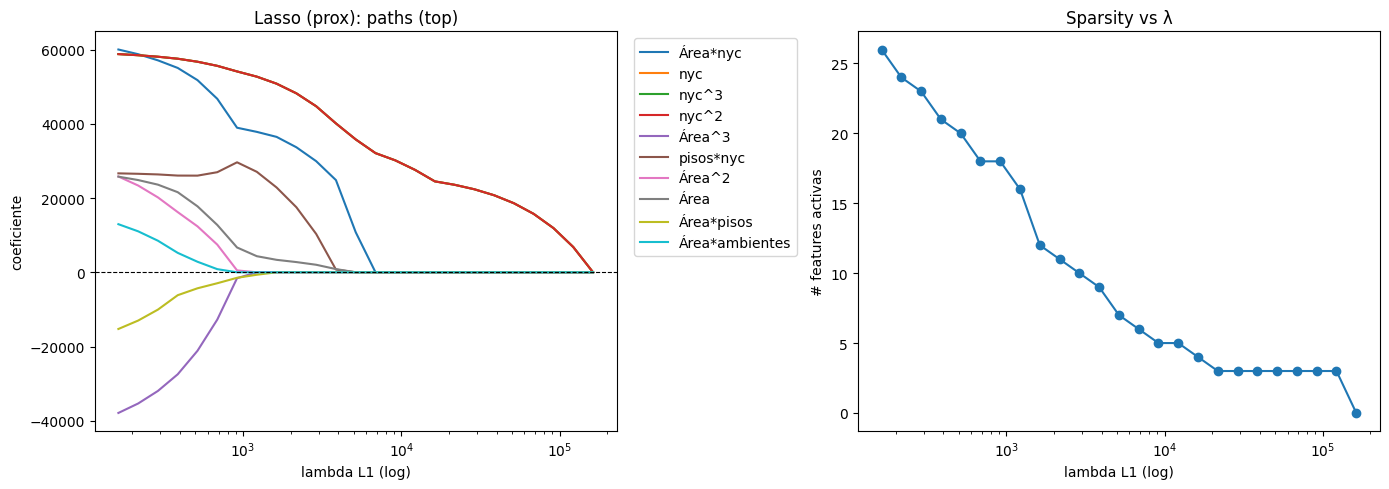

In [119]:
# Barrido Lasso (L1) y comparación (con proximal gradient y warm-start)
import numpy as np

# lambda_max según X centrada (sin bias) y y centrado
def lasso_lambda_max(X, y):
    Xc = X - X.mean(axis=0, keepdims=True)
    yc = y - y.mean()
    n = len(y)
    return (2.0 / n) * np.max(np.abs(Xc.T @ yc))

lam_max = lasso_lambda_max(X_tr, y_tr)
lambdas_l1 = np.geomspace(lam_max, lam_max*1e-3, 25)

mse_tr_l1, mse_va_l1 = [], []
coefs_list_l1 = []
prev = None

for lam in lambdas_l1:
    model = RegresionLineal(
        X_tr, y_tr,
        feature_names=["Intercepto"] + feat_cols if 'feat_cols' in globals() else None,
        lambda_l1=float(lam)
    )
    if prev is not None:
        model.coef_ = prev.copy()  # warm-start
    model.fit_gradiente(lr=5e-3, n_iter=60000, tol=1e-7)
    yhat_tr = model.predict(X_tr); yhat_va = model.predict(X_va)
    mse_tr_l1.append(mse(y_tr, yhat_tr))
    mse_va_l1.append(mse(y_va, yhat_va))
    coefs_list_l1.append(model.coef_)
    prev = model.coef_

plt.figure(figsize=(6,4))
if 'lambdas_l2' in globals() and 'mse_va_arr' in globals():
    plt.semilogx(lambdas_l2, mse_va_arr, label="Ridge (val)")
plt.semilogx(lambdas_l1, mse_va_l1, label="Lasso (val)")
plt.xlabel("lambda (log)"); plt.ylabel("ECM val (USD²)"); plt.title("Ridge vs Lasso (validación)")
plt.legend(); plt.tight_layout(); plt.show()

# Paths de coeficientes y conteo de activos
if coefs_list_l1:
    coefs_arr_l1 = np.vstack([c.reshape(1,-1) for c in coefs_list_l1])
    feat_labels = feat_cols if 'feat_cols' in globals() else [f"x{j}" for j in range(coefs_arr_l1.shape[1]-1)]

    # top-k por |coef| al λ más chico (más flexible)
    abs_at_small_l1 = np.abs(coefs_arr_l1[-1, 1:])
    k = min(10, abs_at_small_l1.shape[0])
    top_idx = np.argsort(-abs_at_small_l1)[:k]

    fig, axes = plt.subplots(1, 2, figsize=(14,5))
    ax0, ax1 = axes

    for j in top_idx:
        label_j = feat_labels[j] if j < len(feat_labels) else f"x{j}"
        ax0.semilogx(lambdas_l1, coefs_arr_l1[:, 1+j], label=label_j)
    ax0.axhline(0, color='k', linewidth=0.8, linestyle='--')
    ax0.set_xlabel("lambda L1 (log)"); ax0.set_ylabel("coeficiente"); ax0.set_title("Lasso (prox): paths (top)")
    ax0.legend(bbox_to_anchor=(1.02,1), loc="upper left")

    # conteo de features activas (excluye intercepto)
    nnz = (np.abs(coefs_arr_l1[:,1:]) > 1e-12).sum(axis=1)
    ax1.semilogx(lambdas_l1, nnz, marker='o')
    ax1.set_xlabel("lambda L1 (log)"); ax1.set_ylabel("# features activas"); ax1.set_title("Sparsity vs λ")
    fig.tight_layout(); plt.show()
else:
    print("No hay coeficientes para graficar paths de Lasso.")


### 5.3 — Selección de λ por Validación Cruzada (Ridge y Lasso)

- Objetivo: elegir λ* que minimiza el ECM medio de CV-5fold para cada regularizador, y evaluar en validación.


In [120]:
# 5.3 (CV-5fold con λ_max, estandarización por fold y warm-start para L1)
import numpy as np
from metrics import mse, rmse
from models import RegresionLineal

# K-fold indices (determinístico)
def _kfold_indices(n, k=5, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(n); rng.shuffle(idx)
    folds = np.array_split(idx, k)
    for i in range(k):
        val_idx = folds[i]
        tr_idx  = np.concatenate([folds[j] for j in range(k) if j != i])
        yield tr_idx, val_idx

# Estandarización por fold (con stats del fold-train)
def _standardize_fold(Xt, Xv):
    mu = Xt.mean(axis=0)
    sd = Xt.std(axis=0)
    sd[sd == 0] = 1.0
    return (Xt - mu)/sd, (Xv - mu)/sd

# λ_max para LASSO (sin intercepto)
def _lasso_lambda_max(X, y):
    Xc = X - X.mean(axis=0, keepdims=True)
    yc = y - y.mean()
    n = len(y)
    return (2.0 / n) * np.max(np.abs(Xc.T @ yc))

# CV genérica (Ridge/Lasso) con estandarización por fold y warm-start para L1)
def _cv_linear_reg(X, y, lambdas, kind="ridge", k=5, lr=5e-3, n_iter=60000, tol=1e-7):
    means, stds = [], []
    for lam in lambdas:
        fold_mses = []
        prev = None
        for tr_idx, va_idx in _kfold_indices(X.shape[0], k=k, seed=42):
            Xt, yt = X[tr_idx], y[tr_idx]
            Xv, yv = X[va_idx], y[va_idx]
            Xt_s, Xv_s = _standardize_fold(Xt, Xv)
            if kind == "ridge":
                mdl = RegresionLineal(Xt_s, yt, lambda_l2=float(lam)).fit_pseudoinversa()
            else:
                mdl = RegresionLineal(Xt_s, yt, lambda_l1=float(lam))
                if prev is not None:
                    mdl.coef_ = prev.copy()
                mdl.fit_gradiente(lr=lr, n_iter=n_iter, tol=tol)
                prev = mdl.coef_.copy()
            yhat = mdl.predict(Xv_s)
            fold_mses.append(mse(yv, yhat))
        means.append(np.mean(fold_mses)); stds.append(np.std(fold_mses))
    return np.array(means), np.array(stds)

# Grillas coherentes y evaluación
grid_l2 = np.logspace(-3, 3, 20)
lam_max = _lasso_lambda_max(X_tr, y_tr)
grid_l1 = np.geomspace(lam_max, lam_max*1e-3, 25)

cv_mean_l2, cv_std_l2 = _cv_linear_reg(X_tr, y_tr, grid_l2, kind="ridge", k=5)
cv_mean_l1, cv_std_l1 = _cv_linear_reg(X_tr, y_tr, grid_l1, kind="lasso", k=5, lr=5e-3, n_iter=60000, tol=1e-7)

best_idx_l2 = int(np.argmin(cv_mean_l2)); lambda_star_l2 = float(grid_l2[best_idx_l2])
best_idx_l1 = int(np.argmin(cv_mean_l1)); lambda_star_l1 = float(grid_l1[best_idx_l1])

print(f"λ* Ridge = {lambda_star_l2:.5f} | MSE_cv = {cv_mean_l2[best_idx_l2]:.2f} ± {cv_std_l2[best_idx_l2]:.2f}")
print(f"λ* Lasso = {lambda_star_l1:.5f} | MSE_cv = {cv_mean_l1[best_idx_l1]:.2f} ± {cv_std_l1[best_idx_l1]:.2f}")

# Entrenar con λ* y evaluar en validación
m6_ridge = RegresionLineal(X_tr, y_tr, lambda_l2=lambda_star_l2).fit_pseudoinversa()
m6_lasso = RegresionLineal(X_tr, y_tr, lambda_l1=lambda_star_l1)
m6_lasso.fit_gradiente(lr=5e-3, n_iter=60000, tol=1e-7)

print(f"M6-Ridge RMSE val = {rmse(y_va, m6_ridge.predict(X_va)):.2f}")
print(f"M6-Lasso RMSE val = {rmse(y_va, m6_lasso.predict(X_va)):.2f}")

λ* Ridge = 0.69519 | MSE_cv = 1945977968.14 ± 252698531.99
λ* Lasso = 162.92328 | MSE_cv = 1940828742.12 ± 256723596.41
M6-Ridge RMSE val = 39745.43
M6-Lasso RMSE val = 39592.32
M6-Ridge RMSE val = 39745.43
M6-Lasso RMSE val = 39592.32


### 5.4 — Comparación final Ridge vs Lasso y definición de M6

- Se sintetizan resultados de CV, se comparan RMSE de validación y se define M6 como el mejor regularizado.


λ* Ridge (CV-5fold) = 0.69519 | MSE_cv = 1945977968.14 ± 252698531.99
λ* Lasso (CV-5fold) = 162.92328 | MSE_cv = 1940828742.12 ± 256723596.41


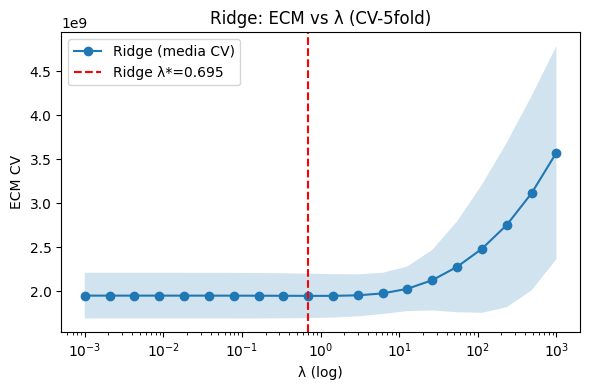

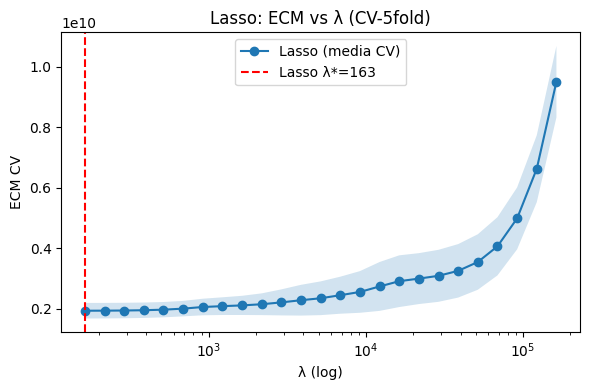


M6-Ridge (λ*=0.695)  | RMSE train=43054.83 | RMSE val=39745.43
M6-Lasso (λ*=163)  | RMSE train=43110.70 | RMSE val=39592.32

>>> M6 seleccionado: Lasso con λ*=163 (mejor RMSE en validación)


In [125]:
# 5.4 — Comparación final Ridge vs Lasso y definición de M6 (conclusión de regularización)
import numpy as np
import matplotlib.pyplot as plt
from metrics import mse, rmse
from models import RegresionLineal

feat_names_full = ["Intercepto"] + list(m5_tmp.features_)

# Definir grillas de λ
def _lasso_lambda_max(X, y):
    Xc = X - X.mean(axis=0, keepdims=True)
    yc = y - y.mean()
    n = len(y)
    return (2.0 / n) * np.max(np.abs(Xc.T @ yc))

grid_l2 = np.logspace(-3, 3, 20)
lam_max = _lasso_lambda_max(X_tr, y_tr)
grid_l1 = np.geomspace(lam_max, lam_max*1e-3, 25)

# CV para Ridge
def _kfold_indices(n, k=5, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(n); rng.shuffle(idx)
    folds = np.array_split(idx, k)
    for i in range(k):
        val_idx = folds[i]
        tr_idx  = np.concatenate([folds[j] for j in range(k) if j != i])
        yield tr_idx, val_idx

def _standardize_fold(Xt, Xv):
    mu = Xt.mean(axis=0)
    sd = Xt.std(axis=0)
    sd[sd == 0] = 1.0
    return (Xt - mu)/sd, (Xv - mu)/sd

def _cv_linear_reg(X, y, lambdas, kind="ridge", k=5, lr=5e-3, n_iter=60000, tol=1e-7):
    means, stds = [], []
    for lam in lambdas:
        fold_mses = []
        prev = None
        for tr_idx, va_idx in _kfold_indices(X.shape[0], k=k, seed=42):
            Xt, yt = X[tr_idx], y[tr_idx]
            Xv, yv = X[va_idx], y[va_idx]
            Xt_s, Xv_s = _standardize_fold(Xt, Xv)
            if kind == "ridge":
                mdl = RegresionLineal(Xt_s, yt, lambda_l2=float(lam)).fit_pseudoinversa()
            else:
                mdl = RegresionLineal(Xt_s, yt, lambda_l1=float(lam))
                if prev is not None:
                    mdl.coef_ = prev.copy()
                mdl.fit_gradiente(lr=lr, n_iter=n_iter, tol=tol)
                prev = mdl.coef_.copy()
            yhat = mdl.predict(Xv_s)
            fold_mses.append(mse(yv, yhat))
        means.append(np.mean(fold_mses)); stds.append(np.std(fold_mses))
    return np.array(means), np.array(stds)

cv_mean_l2, cv_std_l2 = _cv_linear_reg(X_tr, y_tr, grid_l2, kind="ridge", k=5)
cv_mean_l1, cv_std_l1 = _cv_linear_reg(X_tr, y_tr, grid_l1, kind="lasso", k=5)

best_idx_l2 = int(np.argmin(cv_mean_l2))
lambda_star_l2 = float(grid_l2[best_idx_l2])

best_idx_l1 = int(np.argmin(cv_mean_l1))
lambda_star_l1 = float(grid_l1[best_idx_l1])

print(f"λ* Ridge (CV-5fold) = {lambda_star_l2:.5f} | MSE_cv = {cv_mean_l2[best_idx_l2]:.2f} ± {cv_std_l2[best_idx_l2]:.2f}")
print(f"λ* Lasso (CV-5fold) = {lambda_star_l1:.5f} | MSE_cv = {cv_mean_l1[best_idx_l1]:.2f} ± {cv_std_l1[best_idx_l1]:.2f}")

# Gráficos ECM vs λ
plt.figure(figsize=(6,4))
plt.semilogx(grid_l2, cv_mean_l2, marker='o', label='Ridge (media CV)')
plt.fill_between(grid_l2, cv_mean_l2-cv_std_l2, cv_mean_l2+cv_std_l2, alpha=0.2)
plt.axvline(lambda_star_l2, color='r', linestyle='--', label=f'Ridge λ*={lambda_star_l2:.3g}')
plt.xlabel("λ (log)"); plt.ylabel("ECM CV"); plt.title("Ridge: ECM vs λ (CV-5fold)")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
plt.semilogx(grid_l1, cv_mean_l1, marker='o', label='Lasso (media CV)')
plt.fill_between(grid_l1, cv_mean_l1-cv_std_l1, cv_mean_l1+cv_std_l1, alpha=0.2)
plt.axvline(lambda_star_l1, color='r', linestyle='--', label=f'Lasso λ*={lambda_star_l1:.3g}')
plt.xlabel("λ (log)"); plt.ylabel("ECM CV"); plt.title("Lasso: ECM vs λ (CV-5fold)")
plt.legend(); plt.tight_layout(); plt.show()

# Entrenamiento final con λ* y evaluación en VALIDACIÓN
m6_ridge = RegresionLineal(X_tr, y_tr, feature_names=feat_names_full, lambda_l2=lambda_star_l2)
m6_ridge.fit_pseudoinversa()
rmse_tr_ridge = rmse(y_tr, m6_ridge.predict(X_tr))
rmse_va_ridge = rmse(y_va, m6_ridge.predict(X_va))

m6_lasso = RegresionLineal(X_tr, y_tr, feature_names=feat_names_full, lambda_l1=lambda_star_l1)
m6_lasso.fit_gradiente(lr=5e-3, n_iter=60000)
rmse_tr_lasso = rmse(y_tr, m6_lasso.predict(X_tr))
rmse_va_lasso = rmse(y_va, m6_lasso.predict(X_va))

print(f"\nM6-Ridge (λ*={lambda_star_l2:.3g})  | RMSE train={rmse_tr_ridge:.2f} | RMSE val={rmse_va_ridge:.2f}")
print(f"M6-Lasso (λ*={lambda_star_l1:.3g})  | RMSE train={rmse_tr_lasso:.2f} | RMSE val={rmse_va_lasso:.2f}")

# Elegir M6 según mejor RMSE val
if rmse_va_ridge <= rmse_va_lasso:
    M6 = m6_ridge; M6_kind = "Ridge"; M6_lambda = lambda_star_l2
else:
    M6 = m6_lasso; M6_kind = "Lasso"; M6_lambda = lambda_star_l1

print(f"\n>>> M6 seleccionado: {M6_kind} con λ*={M6_lambda:.3g} (mejor RMSE en validación)")

### 6 — Selección final y evaluación en test

- Se comparan M1–M5 y el M6 regularizado usando RMSE en validación.
- Se elige el mejor y se reentrena en todo `dev` (train+val) para evaluar en `test`.


### 6.1 — Learning Curves (M1, M2, M4, M5, M6)

Se grafican curvas de aprendizaje (RMSE vs tamaño de muestra) para analizar sesgo/varianza y la brecha train–val.

- M1/M2: capacidad baja; si la brecha es chica y ambos RMSE se estabilizan alto, hay sesgo.
- M4/M5: mayor capacidad; si la brecha es grande y RMSE val no baja, hay varianza.
- M6 (regularizado): debe reducir la brecha y estabilizar mejor que su contraparte sin regularización.


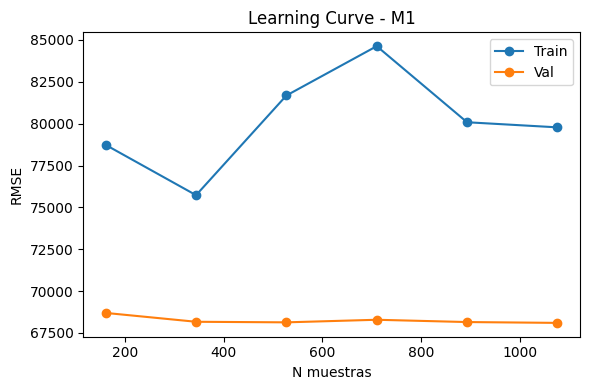

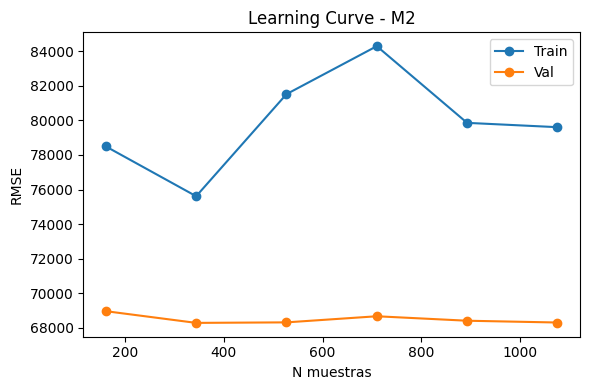

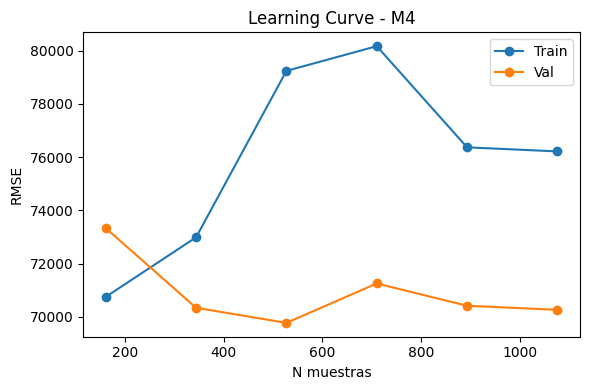

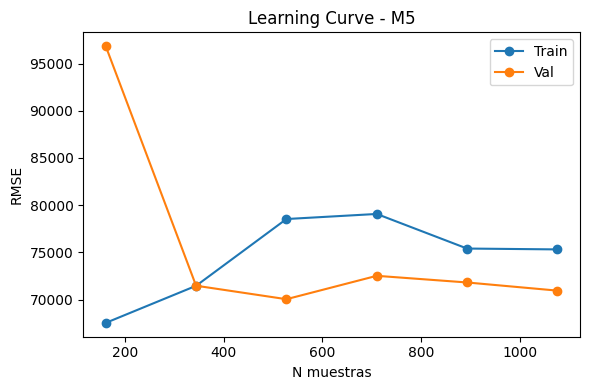

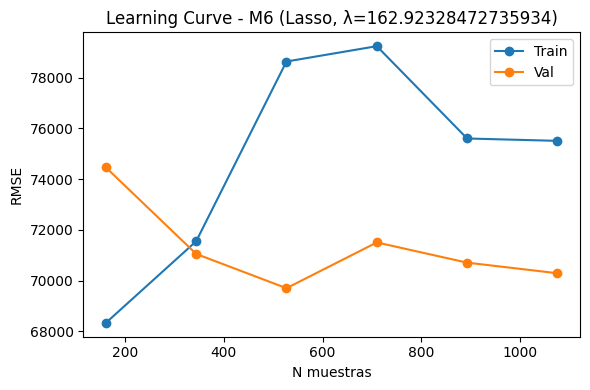

In [122]:
# Learning curves para M1, M2, M4, M5 y M6
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sys
if '../src' not in sys.path:
    sys.path.append('../src')

from utils import learning_curve, plot_learning_curve
from models import M4, M5, RegresionLineal

# Datos
df_tr = pd.read_csv("../data/processed/casas_train.csv").copy()
df_va = pd.read_csv("../data/processed/casas_val.csv").copy()

# Builder de diseños para cada tag
from models import M4, M5
m4_tmp = M4(random_state=42)
m5_tmp = M5(random_state=42).fit(df_tr)
feat_cols_m5 = m5_tmp.features_

def build_Xy(tag, df):
    y = df["precio"].to_numpy() if "precio" in df.columns else None
    if tag == "M1":
        cols = ["Área"]
        X = df[cols].astype(float).to_numpy(); f_names = ["Intercepto"] + cols
        return X, y, f_names
    if tag == "M2":
        cols = ["Área", "pileta"]
        for c in cols:
            if c not in df.columns: df[c] = 0.0
        X = df[cols].astype(float).to_numpy(); f_names = ["Intercepto"] + cols
        return X, y, f_names
    if tag == "M4":
        Xdf = m4_tmp._build_features(df).astype(float)
        return Xdf.to_numpy(), y, ["Intercepto"] + list(Xdf.columns)
    if tag in ("M5", "M6"):
        Xdf = m5_tmp._build_features(df).reindex(columns=feat_cols_m5, fill_value=0.0).astype(float)
        return Xdf.to_numpy(), y, ["Intercepto"] + list(Xdf.columns)
    raise ValueError("tag desconocido")

# Puntos de curva (5–7 puntos)
sizes_frac = np.linspace(0.15, 1.0, 6)

# M1
sizes_n, rmse_tr, rmse_va = learning_curve(build_Xy, "M1", df_tr, df_va, sizes_frac)
plot_learning_curve(sizes_n, rmse_tr, rmse_va, title="Learning Curve - M1")

# M2
sizes_n, rmse_tr, rmse_va = learning_curve(build_Xy, "M2", df_tr, df_va, sizes_frac)
plot_learning_curve(sizes_n, rmse_tr, rmse_va, title="Learning Curve - M2")

# M4
sizes_n, rmse_tr, rmse_va = learning_curve(build_Xy, "M4", df_tr, df_va, sizes_frac)
plot_learning_curve(sizes_n, rmse_tr, rmse_va, title="Learning Curve - M4")

# M5
sizes_n, rmse_tr, rmse_va = learning_curve(build_Xy, "M5", df_tr, df_va, sizes_frac)
plot_learning_curve(sizes_n, rmse_tr, rmse_va, title="Learning Curve - M5")

# M6 (usa el tipo y lambda seleccionado si están definidos)
if 'M6_kind' in globals() and 'M6_lambda' in globals():
    from metrics import rmse
    # precomputo val
    Xv, yv, _ = build_Xy("M6", df_va)
    n = len(df_tr)
    sizes_n = np.unique([max(20, int(fr*n)) for fr in sizes_frac])
    rmse_tr_m6, rmse_va_m6 = [], []
    rng = np.random.default_rng(42)
    idx = np.arange(n); rng.shuffle(idx)
    for m in sizes_n:
        take = idx[:m]
        Xtr, ytr, f_names_tr = build_Xy("M6", df_tr.iloc[take])
        if M6_kind == 'Ridge':
            model = RegresionLineal(Xtr, ytr, feature_names=f_names_tr, lambda_l2=float(M6_lambda)).fit_pseudoinversa()
        elif M6_kind == 'Lasso':
            model = RegresionLineal(Xtr, ytr, feature_names=f_names_tr, lambda_l1=float(M6_lambda)).fit_gradiente(lr=5e-3, n_iter=60000)
        else:
            model = RegresionLineal(Xtr, ytr, feature_names=f_names_tr).fit_pseudoinversa()
        rmse_tr_m6.append(rmse(ytr, model.predict(Xtr)))
        rmse_va_m6.append(rmse(yv, model.predict(Xv)))
    plot_learning_curve(sizes_n, np.array(rmse_tr_m6), np.array(rmse_va_m6), title=f"Learning Curve - M6 ({M6_kind}, λ={M6_lambda})")
else:
    print("M6 no definido aún; corré 5.4 para seleccionar λ* y definir M6_kind/M6_lambda.")


In [123]:
# 6.2 - Selección del modelo para producción (en base a RMSE de validación con n completo)
from metrics import rmse
from models import RegresionLineal

# Requisitos previos del notebook
if 'build_Xy' not in globals():
    raise RuntimeError("Falta build_Xy. Ejecutá 6.1 (learning curves) antes de 6.2.")
if 'df_tr' not in globals() or 'df_va' not in globals():
    raise RuntimeError("Faltan df_tr/df_va. Ejecutá la sección 5.0 (setup) antes de 6.2.")

# Función para entrenar en train completo y evaluar en validación
def final_val_rmse(tag: str):
    Xtr, ytr, ftr = build_Xy(tag, df_tr)
    Xva, yva, fva = build_Xy(tag, df_va)

    if tag == 'M6':
        if 'M6_kind' in globals() and 'M6_lambda' in globals():
            if M6_kind == 'Ridge':
                mdl = RegresionLineal(Xtr, ytr, feature_names=ftr, lambda_l2=float(M6_lambda))
                mdl.fit_pseudoinversa()
            elif M6_kind == 'Lasso':
                mdl = RegresionLineal(Xtr, ytr, feature_names=ftr, lambda_l1=float(M6_lambda))
                mdl.fit_gradiente(lr=5e-3, n_iter=60000, tol=1e-7)
            else:
                mdl = RegresionLineal(Xtr, ytr, feature_names=ftr).fit_pseudoinversa()
        else:
            # Si M6 no fue definido aún, caemos al modelo sin regularización para no frenar el flujo
            mdl = RegresionLineal(Xtr, ytr, feature_names=ftr).fit_pseudoinversa()
    else:
        mdl = RegresionLineal(Xtr, ytr, feature_names=ftr).fit_pseudoinversa()

    yhat = mdl.predict(Xva)
    return rmse(yva, yhat), mdl

# Evaluación comparativa
scores = {}
models = {}
for tag in ['M1', 'M2', 'M4', 'M5']:
    r, mdl = final_val_rmse(tag)
    scores[tag] = r
    models[tag] = mdl

if 'M6_kind' in globals():
    r, mdl = final_val_rmse('M6')
    scores['M6'] = r
    models['M6'] = mdl

print('RMSE validación (n train completo):')
for k in scores:
    print(f"  {k:>3}: {scores[k]:.2f}")

selected_tag = min(scores, key=scores.get)
selected_model = models[selected_tag]
print(f"\nModelo seleccionado para producción según RMSE val: {selected_tag}")

RMSE validación (n train completo):
   M1: 68102.73
   M2: 68314.49
   M4: 70258.97
   M5: 70956.80
   M6: 70293.45

Modelo seleccionado para producción según RMSE val: M1


In [124]:
# 6.3 - Evaluación en TEST: MAE y RMSE del modelo seleccionado
import pandas as pd
import numpy as np

def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))

# Cargar test
df_test = pd.read_csv("../data/processed/casas_test.csv").copy()
df_test = agregar_ciudad(df_test)

# Construir diseño según el modelo elegido
def build_X_for_tag(tag, df):
    X, _, f = build_Xy(tag, df)
    return X

X_te = build_X_for_tag(selected_tag, df_test)

# Entrenar el modelo final en TODO dev (train+val) para evaluar en test
df_dev = pd.read_csv("../data/processed/casas_dev.csv").copy()
df_dev = agregar_ciudad(df_dev)
X_dev, y_dev, f_dev = build_Xy(selected_tag, df_dev)

if selected_tag == "M6":
    if M6_kind == "Ridge":
        mdl_final = RegresionLineal(X_dev, y_dev, feature_names=f_dev, lambda_l2=float(M6_lambda))
        mdl_final.fit_pseudoinversa()
    else:
        mdl_final = RegresionLineal(X_dev, y_dev, feature_names=f_dev, lambda_l1=float(M6_lambda))
        mdl_final.fit_gradiente(lr=1e-2, n_iter=20000)
else:
    mdl_final = RegresionLineal(X_dev, y_dev, feature_names=f_dev).fit_pseudoinversa()

# Si el test tiene precio, calculamos métricas; si no, solo reportamos que no se puede evaluar
if "precio" in df_test.columns:
    y_te = df_test["precio"].to_numpy()
    yhat_te = mdl_final.predict(X_te)
    mae_te = mae(y_te, yhat_te)
    rmse_te = rmse(y_te, yhat_te)
    print(f"{selected_tag} en TEST → MAE = {mae_te:.2f} | RMSE = {rmse_te:.2f}")
else:
    print("El conjunto de test no tiene 'precio'; no se evalúa en test y no se generan archivos de predicciones.")


M1 en TEST → MAE = 52295.21 | RMSE = 79572.91


## Conclusiones

- El preprocesamiento (unificación de unidades y normalización por train) estabiliza la relación área–precio y mejora la comparabilidad.
- Los modelos base confirman el poder explicativo del tamaño y el efecto de `pileta`.
- El modelo completo mejora respecto del básico; la matriz de correlación sugiere multicolinealidad entre `Área` y `metros_cubiertos`.
- La regularización con CV permite seleccionar λ y definir M6 (Ridge/Lasso) con mejor equilibrio sesgo–varianza en validación.
- El modelo final se reentrena en todo `dev` y se evalúa en `test` reportando métricas, sin generar archivos de predicciones.